# 2.5c — C# — Equite par sous-groupe : compromis performance-parite, et pourquoi l'accuracy globale ne suffit pas

**Navigation** : [<< 2.5b-Calibration-Probabilites](2.5b-Calibration-Probabilites-CSharp.ipynb) | [2.5d-Derive-Distribution-Deploiement →](2.5d-Derive-Distribution-Deploiement.ipynb) | [Index](README.md) | [2.6-Clustering-KMeans-PCA >>](2.6-Clustering-KMeans-PCA.ipynb)

**Kernel** : .NET Interactive — C# · **Duree indicative** : 60–90 min avec les exercices

## Introduction

Les notebooks precedents ont appris a **mesurer** un modele. [2.5](2.5-Biais-Variance-CV-ROC.ipynb) pose l'accuracy et la courbe ROC ; [2.5b](2.5b-Calibration-Probabilites-CSharp.ipynb) ajoute le **reliability diagram** et l'**ECE** pour verifier qu'un score de 0.87 veut bien dire « 87 % de chances » ; [2.13](2.13-Analyse-Erreurs.ipynb) introduit le **geste du praticien** : decouper la performance par tranches et chercher la poche d'erreur que la moyenne cache. Ce notebook ferme la boucle en posant la question qui manque : **pour qui** le modele a-t-il raison ?

Une accuracy globale de 82 % peut fort bien s'accompagner d'un taux d'erreur de 35 % sur un sous-groupe de la population — exactement la situation que [2.13](2.13-Analyse-Erreurs.ipynb) apprend a detecter. Mais ici, l'erreur n'est pas aleatoire : elle **suit un attribut sensible** (age, genre, origine). Le modele devient alors **biaise structurellement**, et les metriques agregees ne suffisent plus à décrire les sous-groupes : dire « mon modele est correct a 82 % » sans dire « pour qui » revient a confondre moyenne et population. L'**equite par sous-groupe** (*fairness*) est la discipline qui mesure cet ecart, en propose des definitions formelles, et — surtout — étudie les conditions sous lesquelles certaines exigences entrent en tension.

Trois lecons a retenir :

1. **Mesurer separement, pas agreger.** Une accuracy globale de 80 % avec 5 % d'erreur chez les uns et 35 % chez les autres n'est **pas** un bon modele — c'est un modele moyen qui oublie une moitie de la population.
2. **Trois definitions, trois exigences differentes.** *Demographic parity* (meme taux de predictions positives), *equal opportunity* (meme taux de vrais positifs parmi les positifs reels), *equalized odds* (meme taux de vrais ET faux positifs). Une metrique d'equite **choisie a priori** vaut mieux qu'une metrique d'equite **calculee a posteriori pour flatter le resultat**.
3. **Le compromis se mesure.** Réduire un écart de parité peut modifier l’accuracy dans un sens ou dans l’autre ; une perte n’est pas inévitable — l'arbitrage est *quantitatif et depend du contexte*, pas un debat moral. Le praticien qui sait nommer ce compromis est plus utile que celui qui proclame « mon modele est equitable » sans preciser *selon quelle definition* et *a quel cout*.

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :

- **Choisir** une definition d'equite adaptee au contexte (parite demographique, egalite des chances, chances egalisees) ;
- **Mesurer** les trois metriques sur un cas synthetique a la main (table de contingence), puis avec bootstrap ;
- **Construire** un cas ou calibration, accuracy et parite entrent en conflit ;
- **Comparer** au moins deux mitigations (reweighting et seuils par groupe) sur le meme split ;
- **Tracer** la frontiere de compromis performance-equite et lire un verdict contextualise.

### Pre-requis

- [2.5 — Biais-Variance-CV-ROC](2.5-Biais-Variance-CV-ROC.ipynb) : accuracy, ROC, AUC, matrice de confusion.
- [2.5b — Calibration-Probabilites](2.5b-Calibration-Probabilites-CSharp.ipynb) : reliability diagram, ECE, Brier score.
- [2.13 — Analyse-Erreurs](2.13-Analyse-Erreurs.ipynb) : poches d'erreur, diagnostic par tranches.

### Position dans l'arc pedagogique

Ce notebook prolonge l'**unite donnees desequilibrees + calibration + analyse d'erreurs** sans les dupliquer. La parite demographique joue le meme role qu'un taux de base asymetrique (notebook 2.13) : reveler ce que la moyenne cache. L'equite s'ajoute aux trois metriques classiques (accuracy, calibration, discrimination) comme une **quatrieme exigence** qu'aucune des trois ne garantit.

**Politique de portage.** Python.NET 3.1.0 appelle les vrais `LogisticRegression`, `CalibratedClassifierCV` et `FrozenEstimator` (CPython compatible, NumPy et scikit-learn >=1.6). NumPy/sklearn fournissent les mêmes tirages et indices de séparation. C# calcule confusion, métriques, 200 bootstraps, bins quantiles, reweighting, recherche des 95 seuils, intervalles Wilson et figures SVG. Les modèles n’engloutissent pas le parcours pédagogique dans un wrapper Python.


In [1]:
// CPython fournit les vrais estimateurs sklearn ; les métriques et figures restent natives.
#r "nuget: pythonnet, 3.1.0"
#load "../../../Config/PythonNetLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text;
using System.Text.Json;
using System.Globalization;
using System.Security;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;

public record EquitySvg(string Value);
Formatter.Register<EquitySvg>((value, writer) => writer.Write(value.Value), "image/svg+xml");
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "sklearn");
    PythonEngine.BeginAllowThreads();
}

JsonElement Backend(string code, object config)
{
    // Le résultat JSON est détaché du scope avant libération sous le GIL.
    using (Py.GIL())
    {
        using var scope = Py.CreateScope();
        using var input = new PyString(JsonSerializer.Serialize(config));
        scope.Set("config_json", input);
        scope.Exec("import json, numpy as np\ncfg=json.loads(config_json)\n" + code);
        using var result = scope.Get("result_json");
        using var document = JsonDocument.Parse(result.As<string>());
        return document.RootElement.Clone();
    }
}

double[] Doubles(JsonElement x) => x.EnumerateArray().Select(v => v.GetDouble()).ToArray();
int[] Ints(JsonElement x) => x.EnumerateArray().Select(v => v.GetInt32()).ToArray();
double[][] Matrix(JsonElement x) => x.EnumerateArray().Select(Doubles).ToArray();
// SVG opaque : titres, unités, légende et graduations restent visibles sur GitHub.
EquitySvg SvgChart(string title, string xLabel, string yLabel, (string Name, double[] X, double[] Y, string Color)[] curves, double xMin = 0, double xMax = 1, double yMin = 0, double yMax = 1, bool bars = false)
{
    string E(string s) => SecurityElement.Escape(s) ?? "";
    double PX(double x) => 75 + 580 * (x - xMin) / (xMax - xMin);
    double PY(double y) => 375 - 290 * (y - yMin) / (yMax - yMin);
    var s = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='760' height='470' viewBox='0 0 760 470'><rect width='760' height='470' fill='white'/><g font-family='sans-serif' font-size='12' fill='#202020'>");
    s.Append($"<text x='380' y='24' text-anchor='middle' font-size='16'>{E(title)}</text>");
    for (int k = 0; k <= 5; k++)
    {
        double x = xMin + k * (xMax - xMin) / 5;
        double y = yMin + k * (yMax - yMin) / 5;
        s.Append($"<path d='M75 {PY(y):F3}H655' stroke='#ddd'/><text x='67' y='{PY(y) + 4:F3}' text-anchor='end'>{y:G3}</text>");
        s.Append($"<text x='{PX(x):F3}' y='395' text-anchor='middle'>{x:G3}</text>");
    }

    s.Append("<path d='M75 85V375H655' fill='none' stroke='#333'/>");
    s.Append($"<text x='365' y='424' text-anchor='middle'>{E(xLabel)}</text><text transform='translate(18 230) rotate(-90)' text-anchor='middle'>{E(yLabel)}</text>");
    for (int j = 0; j < curves.Length; j++)
    {
        var c = curves[j];
        var points = Enumerable.Range(0, c.X.Length).Where(i => double.IsFinite(c.X[i]) && double.IsFinite(c.Y[i])).ToArray();
        if (bars)
        {
            foreach (var i in points)
                s.Append($"<rect x='{PX(c.X[i]) - 13:F3}' y='{PY(c.Y[i]):F3}' width='26' height='{375 - PY(c.Y[i]):F3}' fill='{c.Color}' stroke='white'/>");
        }
        else
        {
            var xy = string.Join(" ", points.Select(i => $"{PX(c.X[i]):F3},{PY(c.Y[i]):F3}"));
            s.Append($"<polyline points='{xy}' fill='none' stroke='{c.Color}' stroke-width='2'/>");
            if (c.X.Length <= 20)
                foreach (var i in points)
                    s.Append($"<circle cx='{PX(c.X[i]):F3}' cy='{PY(c.Y[i]):F3}' r='3' fill='{c.Color}'/>");
        }

        s.Append($"<path d='M{85 + j * 210} 449h18' stroke='{c.Color}' stroke-width='3'/><text x='{110 + j * 210}' y='453'>{E(c.Name)}</text>");
    }

    return new EquitySvg(s.Append("</g></svg>").ToString());
}

Console.WriteLine($".NET {Environment.Version} ; Python.NET {typeof(PythonEngine).Assembly.GetName().Version}");
Console.WriteLine(Backend("import sklearn\nresult_json=json.dumps(dict(numpy=np.__version__,sklearn=sklearn.__version__))", new { }));


Installing Packages pythonnet

.NET 10.0.13 ; Python.NET 3.1.0.0


{"numpy": "2.4.2", "sklearn": "1.9.1"}


***

## 1. Le setup : un modele qui sert tout le monde, ou presque ?

On construit un **scenario synthetique** d'attribution de credit. Deux profils coexistent — `groupe A` (les « jeunes ») et `groupe B` (les « seniors ») — et la **probabilite vraie de defaut** differe entre les deux (taux empiriques à lire séparément sur la population générée et sur le test : le tableau de la section 2 donne **1.3 %** pour A, **5.9 %** pour B et **3.6 %** global sur le test), par construction des coefficients et d’une interaction groupe×ancienneté. Les noms « jeunes » et « seniors » sont des étiquettes fictives ; aucune causalité économique ou propriété réelle d’un groupe d’âge n’est établie.

> **Note pedagogique.** Ces prevalences sont **volontairement basses** (<< 50 %) pour demontrer une limite classique des classifieurs a seuil fixe (cf. section 5) : sur ce tirage et avec ce modèle, tous les scores de test restent sous 0.5, d’où l’absence de prédictions positives. Une faible prévalence ne suffit pas, en général, à imposer ce comportement. C'est exactement la lecon que la baseline nous enseignera — pas un defaut du setup, c'est le **sujet du notebook**.

Le **risque** de ce setup, c'est qu'un modele qui ne tient pas compte du groupe peut quand meme produire un score moyen correct — et discriminer sans qu'aucune metrique agregee ne le revele. C'est exactement ce que [2.13](2.13-Analyse-Erreurs.ipynb) demontrait sur le churn telecom : le piege n'est pas dans le score global, il est dans les sous-populations.

### 1.1 Generation des donnees

On genere `N = 5000` dossiers, avec deux signaux (`revenu_mensuel` et `anciennete_credits`) qui entrent dans le mécanisme simulé de défaut **à l’intérieur de chaque groupe**, mais avec un biais dans la **constante du modele** : les intercepts et l’interaction sont des paramètres imposés par le générateur, sans inférence sur un désavantage historique réel.

In [2]:
// Le vrai RandomState42 conserve le tirage source ; aucune estimation de modèle n'a lieu ici.
var population = Backend(@"
rng=np.random.RandomState(42); n=5000
G=rng.binomial(1,.5,n); income=rng.normal(2500,600,n); seniority=rng.uniform(0,20,n)
z=(-2.2-.0008*income-.06*seniority)*(1-G)+(-1.4-.0006*income-.04*seniority)*G
z=z+1.2*G*(seniority>15)
p=1/(1+np.exp(-z)); y=rng.binomial(1,p)
result_json=json.dumps(dict(g=G.tolist(),X=np.column_stack([income,seniority]).tolist(),y=y.tolist(),p=p.tolist()))
", new { });
var group = Ints(population.GetProperty("g"));
var allX = Matrix(population.GetProperty("X"));
var allY = Ints(population.GetProperty("y"));
var trueProbability = Doubles(population.GetProperty("p"));
Console.WriteLine($"Population synthétique : N={allY.Length}");
Console.WriteLine($"Part B : {group.Average():P2} ; défaut global : {allY.Average():P2}");
for (int g = 0; g < 2; g++)
    Console.WriteLine($"Défaut groupe {(g == 0 ? "A" : "B")} : {Enumerable.Range(0, allY.Length).Where(i => group[i] == g).Average(i => allY[i]):P2}");


Population synthétique : N=5000


Part B : 50.00 % ; défaut global : 3.58 %


Défaut groupe A : 1.32 %


Défaut groupe B : 5.84 %


### 1.2 Split entrainement / calibration / test stratifie

Le test reste **sacre** : le modele est ajuste sur entrainement, les seuils sont choisis sur calibration, et les resultats finaux sont mesures sur test. Ces trois ensembles sont disjoints. On stratifie sur la **variable cible combinee** (groupe × defaut), pour stabiliser les effectifs de chaque sous-groupe et limiter la variabilite liee au decoupage. Un partage aleatoire non stratifie ne serait pas, de ce seul fait, un estimateur systematiquement biaise.

In [3]:
// Stratification croisée groupe×label, puis séparation de calibration à graine43.
var split = Backend(@"
from sklearn.model_selection import train_test_split
indices=np.arange(len(cfg['y'])); strata=np.asarray([str(g)+'_'+str(y) for g,y in zip(cfg['g'],cfg['y'])])
train,test=train_test_split(indices,test_size=.3,random_state=42,stratify=strata)
train,cal=train_test_split(train,test_size=.3,random_state=43,stratify=strata[train])
result_json=json.dumps(dict(train=train.tolist(),cal=cal.tolist(),test=test.tolist()))
", new { y = allY, g = group });
var trainIdx = Ints(split.GetProperty("train"));
// Les indices de calibration restent disjoints du train et du test pour apprendre les seuils.
var calIdx = Ints(split.GetProperty("cal"));
var testIdx = Ints(split.GetProperty("test"));
var XTrain = trainIdx.Select(i => allX[i]).ToArray();
var XCal = calIdx.Select(i => allX[i]).ToArray();
var XTest = testIdx.Select(i => allX[i]).ToArray();
var yTrain = trainIdx.Select(i => allY[i]).ToArray();
var yCal = calIdx.Select(i => allY[i]).ToArray();
var yTest = testIdx.Select(i => allY[i]).ToArray();
var gTrain = trainIdx.Select(i => group[i]).ToArray();
var gCal = calIdx.Select(i => group[i]).ToArray();
var gTest = testIdx.Select(i => group[i]).ToArray();
Console.WriteLine($"Split : {yTrain.Length} train | {yCal.Length} calibration | {yTest.Length} test");
Console.WriteLine($"Défaut train : {yTrain.Average():P2} | test : {yTest.Average():P2}");
Console.WriteLine($"Part B train : {gTrain.Average():P2} | test : {gTest.Average():P2}");


Split : 2450 train | 1050 calibration | 1500 test


Défaut train : 3.55 % | test : 3.60 %


Part B train : 50.00 % | test : 50.00 %


### 1.3 Modele de reference (naif, sans attribut sensible)

On entraine une regression logistique **sur les seuls signaux economiques**. L'attribut `groupe` est volontairement exclu : c'est un modele « aveugle » au groupe, qu'on nommera *baseline*. L'accuracy globale sera elevee ; on comparera les **taux de prediction par groupe** selon les seuils, sans supposer qu'ils divergent dans chaque configuration.

> **Note juridique.** En production, l'attribut sensible peut etre exclu a l'entrainement pour des raisons legales, mais l'**equite doit etre mesuree** sur les decisions produites — l'exclusion ne garantit rien. C'est exactement ce que cette section met en evidence.

In [4]:
// Vraie LogisticRegression, sans standardisation ajoutée au protocole source.
JsonElement FitLogistic(double[] weights = null)
{
    return Backend(@"
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)
model.fit(cfg['XTrain'],cfg['yTrain'],sample_weight=cfg['weights'])
result_json=json.dumps(dict(test=model.predict_proba(cfg['XTest'])[:,1].tolist(),
    cal=model.predict_proba(cfg['XCal'])[:,1].tolist(),intercept=float(model.intercept_[0]),coef=model.coef_[0].tolist()))
", new { XTrain, yTrain, XTest, XCal, weights });
}

var baseline = FitLogistic();
var pTest = Doubles(baseline.GetProperty("test"));
var pCal = Doubles(baseline.GetProperty("cal"));
var yPred = pTest.Select(p => p >= .5 ? 1 : 0).ToArray();
double Accuracy(int[] y, int[] pred) => Enumerable.Range(0, y.Length).Count(i => y[i] == pred[i]) / (double)y.Length;
var coef = Doubles(baseline.GetProperty("coef"));
Console.WriteLine($"Baseline : accuracy globale {Accuracy(yTest, yPred):P2}");
Console.WriteLine($"Intercept={baseline.GetProperty("intercept").GetDouble():F3}, revenu={coef[0]:F5}, ancienneté={coef[1]:F3}");
for (int g = 0; g < 2; g++)
    Console.WriteLine($"Taux positif groupe {(g == 0 ? "A" : "B")} : {Enumerable.Range(0, yTest.Length).Where(i => gTest[i] == g).Average(i => yPred[i]):P2}");


Baseline : accuracy globale 96.40 %


Intercept=-2.191, revenu=-0.00052, ancienneté=0.014


Taux positif groupe A : 0.00 %


Taux positif groupe B : 0.00 %


**Mesure.** Sur ce split, les deux taux de prediction positive valent **0.00 %** : l'ecart est nul, mais pour la mauvaise raison — personne n'est predit positif. C'est le comportement mesure ici au seuil 0.5 : le modele predit toujours l'absence de defaut. Un ecart nul de taux positifs ne renseigne alors ni sur sa capacite a reperer les defauts, ni sur l'egalite des erreurs ; l'accuracy et les faux negatifs restent a examiner. Le mecanisme reste celui annonce : le groupe B a une fréquence de défaut plus élevée dans cette simulation (**5.9 % vs 1.3 %**, cf. tableau de la section 2), et certains seuils produisent des taux par groupe différents sur ce tirage — c'est exactement ce que la frontiere de la section 4.2 montrera en balayant le regime utile du seuil. Le modèle n’a jamais vu l’attribut groupe ; cette omission ne garantit pas l’égalité des métriques. Le diagnostic statistique ne suffit pas à établir une intention ni une qualification juridique.

> **Note.** Dans cette simulation, le modele predit 0 dans les deux groupes au seuil 0.5 ; une faible prevalence n'implique pas universellement ce comportement. DPD et EOD valent 0 non parce que le modele est equitable, mais parce qu'il ne predit jamais positif.

***

## 2. Trois definitions, trois exigences

L'equite par sous-groupe ne se reduit pas a un seul chiffre. Trois definitions coexistent, et elles mesurent des choses differentes :

| Definition | Formule (groupe A vs B) | Ce qu'elle mesure |
|---|---|---|
| **Parite demographique** (DPD) | `P(Y_pred = 1 \| A) = P(Y_pred = 1 \| B)` | Meme **taux de decision** par groupe — indifferent aux etiquettes reelles |
| **Egalite des chances** (EOD sur TPR) | `P(Y_pred = 1 \| A, Y = 1) = P(Y_pred = 1 \| B, Y = 1)` | Meme **taux de vrais positifs** parmi les positifs reels — ici, meme rappel des **defauts**, puisque `Y=1` designe un defaut et non l'octroi d'un credit |
| **Chances egalisees** (EOD complet) | TPR _et_ FPR identiques entre groupes | TPR _et_ FPR equivalents — la plus stricte |

Ces definitions peuvent entrer en conflit, mais ne sont pas toujours incompatibles : un classifieur constant satisfait les trois egalites de taux, de facon triviale. Le praticien doit donc **choisir** celle qui correspond au contexte reglementaire et metier — leur compatibilité dépend des données, du modèle et de la définition choisie.

### 2.1 Petite table controlee : verifier a la main

Construisons d'abord une **table de contingence minimaliste** qui nous permet de verifier a la main les trois metriques, puis on les calculera sur les donnees reelles. Voici 12 dossiers fictifs, ou l'on connait les etiquettes et les predictions :

In [5]:
// Les dénominateurs nuls donnent NaN : une métrique indéfinie n'est pas une parité parfaite.
public record GroupMetrics(int N, int TN, int FP, int FN, int TP, double Accuracy, double TPR, double FPR, double PP, double Prevalence);
GroupMetrics Metrics(int[] y, int[] pred, int[] groups, int label)
{
    var ids = Enumerable.Range(0, y.Length).Where(i => groups[i] == label).ToArray();
    // Le TPR est conditionné par le label réel positif (y=1) ; PP mesure les décisions positives dans tout le groupe.
    int tn = ids.Count(i => y[i] == 0 && pred[i] == 0), fp = ids.Count(i => y[i] == 0 && pred[i] == 1);
    int fn = ids.Count(i => y[i] == 1 && pred[i] == 0), tp = ids.Count(i => y[i] == 1 && pred[i] == 1);
    double Ratio(int k, int n) => n == 0 ? double.NaN : k / (double)n;
    return new GroupMetrics(ids.Length, tn, fp, fn, tp, Ratio(tp + tn, ids.Length), Ratio(tp, tp + fn), Ratio(fp, fp + tn), Ratio(tp + fp, ids.Length), Ratio(tp + fn, ids.Length));
}

void PrintMetrics(string name, GroupMetrics m) => Console.WriteLine($"{name, -12} n={m.N, 4} accuracy={m.Accuracy:F3} TPR={m.TPR:F3} FPR={m.FPR:F3} PP={m.PP:F3} prevalence={m.Prevalence:F3}");
var controlY = new[]
{
    1,
    1,
    1,
    0,
    0,
    0,
    1,
    1,
    1,
    0,
    0,
    0
};
var controlPred = new[]
{
    1,
    1,
    0,
    0,
    0,
    1,
    0,
    0,
    0,
    0,
    0,
    1
};
var controlGroup = Enumerable.Repeat(0, 6).Concat(Enumerable.Repeat(1, 6)).ToArray();
var controlA = Metrics(controlY, controlPred, controlGroup, 0);
var controlB = Metrics(controlY, controlPred, controlGroup, 1);
PrintMetrics("Contrôle A", controlA);
PrintMetrics("Contrôle B", controlB);
Console.WriteLine($"DPD={Math.Abs(controlA.PP - controlB.PP):F2}, EOD={Math.Abs(controlA.TPR - controlB.TPR):F2}, chances égalisées={Math.Max(Math.Abs(controlA.TPR - controlB.TPR), Math.Abs(controlA.FPR - controlB.FPR)):F2}");


Contrôle A   n=   6 accuracy=0.667 TPR=0.667 FPR=0.333 PP=0.500 prevalence=0.500


Contrôle B   n=   6 accuracy=0.333 TPR=0.000 FPR=0.333 PP=0.167 prevalence=0.500


DPD=0.33, EOD=0.67, chances égalisées=0.67


**Lecture de la table.** On observe que, sur cet echantillon minuscule, le groupe A a un TPR de 0.67 (2/3) et un PP de 0.50 (3/6), tandis que le groupe B a un TPR de 0.00 et un PP de 0.17. La parite demographique est a 0.33, l'egalite des chances a 0.67. Aucune des trois metriques n'est satisfaite.

**Pourquoi cette table est utile.** Elle ancre les metriques dans un exemple **verifiable ligne par ligne**. Quand plus tard on calculera ces memes metriques sur 1500 dossiers de test, on aura oublie ce que mesure un TPR. La table de controle rappelle que **TPR = tp/(tp+fn)** se reduit a un comptage de 4 cases.

### 2.2 Metriques sur le modele naif

Maintenant qu'on a verifie la formule, on l'applique aux donnees reelles :

In [6]:
// Les métriques de groupe décomposent la même baseline, sans réentraînement.
var resultA = Metrics(yTest, yPred, gTest, 0);
var resultB = Metrics(yTest, yPred, gTest, 1);
PrintMetrics("Baseline A", resultA);
PrintMetrics("Baseline B", resultB);
Console.WriteLine($"Global : n={yTest.Length}, accuracy={Accuracy(yTest, yPred):F3}, PP={yPred.Average():F3}, prévalence={yTest.Average():F3}");
Console.WriteLine($"DPD={Math.Abs(resultA.PP - resultB.PP):F3} ; EOD={Math.Abs(resultA.TPR - resultB.TPR):F3}");
Console.WriteLine($"Chances égalisées : {Math.Max(Math.Abs(resultA.TPR - resultB.TPR), Math.Abs(resultA.FPR - resultB.FPR)):F3}");


Baseline A   n= 750 accuracy=0.987 TPR=0.000 FPR=0.000 PP=0.000 prevalence=0.013


Baseline B   n= 750 accuracy=0.941 TPR=0.000 FPR=0.000 PP=0.000 prevalence=0.059


Global : n=1500, accuracy=0.964, PP=0.000, prévalence=0.036


DPD=0.000 ; EOD=0.000


Chances égalisées : 0.000


### Exercice ouvert 1 — distinguer les trois écarts

Écrire `FairnessGaps(y, prediction, groups)` qui renvoie, dans cet ordre, DPD, écart absolu de TPR et maximum des écarts absolus TPR/FPR. Réutiliser les métriques explicites, puis calculer à la main le cas où les deux groupes ont TPR=1 mais des FPR de 1 et 0. Les cinq petites tables de contrôle contiennent les deux classes dans chaque groupe : les écarts y sont définis. Une égalité des chances n’implique pas les chances égalisées.

La cellule reste ouverte ; les contrôles finis refusent notamment un résultat constant, une forme incomplète ou NaN. Ils ne remplacent pas l’argumentation sur la définition retenue.


In [7]:
// Empreinte ordonnée de toutes les valeurs quantifiées à 1e-8, compatible avec NumPy rint.
string TraceDigest(IEnumerable<double> values)
{
    var text = string.Join(",", values.Select(v => ((long)Math.Round(v * 1e8, MidpointRounding.ToEven)).ToString(CultureInfo.InvariantCulture)));
    return Convert.ToHexString(System.Security.Cryptography.SHA256.HashData(Encoding.UTF8.GetBytes(text))).ToLowerInvariant();
}

double TraceQuantile(double[] values, double q)
{
    var x = values.OrderBy(v => v).ToArray();
    double position = q * (x.Length - 1);
    int k = (int)position;
    return x[k] + (position - k) * (x[Math.Min(k + 1, x.Length - 1)] - x[k]);
}

// Exercice ouvert : trois écarts distincts, contrôlés sur cinq petites tables.
void Require(bool ok, string message)
{
    if (!ok)
        throw new ArgumentException(message);
}

double[] FairnessGaps(int[] y, int[] prediction, int[] groups)
{
    // TODO : DPD, différence absolue TPR, maximum des différences TPR/FPR.
    return null;
}

var fairnessFixtures = new (int[] Y, int[] P, int[] G, double[] Expected)[]
{
    (new[] { 1, 1, 0, 0, 1, 1, 0, 0 }, new[] { 1, 0, 1, 0, 1, 1, 0, 0 }, new[] { 0, 0, 0, 0, 1, 1, 1, 1 }, new[] { 0.0, 0.5, 0.5 }),
    (new[] { 1, 0, 1, 0, 1, 0, 1, 0 }, new[] { 0, 0, 1, 1, 0, 1, 0, 1 }, new[] { 0, 0, 0, 0, 1, 1, 1, 1 }, new[] { 0.0, 0.5, 0.5 }),
    (new[] { 1, 0, 0, 1, 0, 0 }, new[] { 1, 0, 0, 0, 0, 0 }, new[] { 0, 0, 0, 1, 1, 1 }, new[] { 0.3333333333333333, 1.0, 1.0 }),
    (new[] { 1, 0, 1, 0 }, new[] { 1, 0, 1, 0 }, new[] { 0, 0, 1, 1 }, new[] { 0.0, 0.0, 0.0 }),
    (new[] { 1, 0, 0, 1, 0, 0 }, new[] { 1, 1, 1, 1, 0, 0 }, new[] { 0, 0, 0, 1, 1, 1 }, new[] { 0.6666666666666666, 0.0, 1.0 }),
};
var fairnessAnswers = fairnessFixtures.Select(f => FairnessGaps(f.Y, f.P, f.G)).ToArray();
if (fairnessAnswers.All(r => r == null))
    Console.WriteLine("Exercice1 à compléter : calculer les trois écarts.");
else
{
    for (int k = 0; k < fairnessFixtures.Length; k++)
    {
        var r = fairnessAnswers[k];
        var f = fairnessFixtures[k];
        Require(r != null && r.Length == 3 && r.All(double.IsFinite), "Trois écarts finis requis");
        Require(Enumerable.Range(0, 3).All(i => Math.Abs(r[i] - f.Expected[i]) < 1e-12), "Définition ou table incorrecte");
    }

    Console.WriteLine("Contrat équité satisfait ; justifier le cas TPR égaux/FPR différents.");
}


Exercice1 à compléter : calculer les trois écarts.


***

## 3. Intervalles bootstrap : savoir ce qu'on mesure

Une metrique ponctuelle sur 1500 dossiers ne dit rien de sa **stabilite**. Si je re-echantillonne mon test, j'obtiens une autre valeur — et je veux savoir *combien* elle peut bouger. La technique canonique est le **bootstrap** : on tire avec remise `B = 200` echantillons, on calcule la metrique sur chacun, et on lit l'intervalle de confiance a 95 %.

Le bootstrap **ne remplace pas un split plus grand** : il donne une idee de la **variabilite d'echantillonnage** autour de l'estimation ponctuelle. Si l'intervalle est large, il faut soit plus de donnees, soit accepter une marge d'incertitude.

In [8]:
// RandomState2026 fournit seulement les indices ; C# calcule les 400 lignes de métriques.
var bootstrapData = Backend(@"rng=np.random.RandomState(2026)
result_json=json.dumps(rng.randint(0,cfg['n'],size=(200,cfg['n'])).tolist())", new { n = yTest.Length });
var bootstrapIndices = bootstrapData.EnumerateArray().Select(Ints).ToArray();
var boot = new List<(int Group, int Draw, GroupMetrics Stats)>();
for (int b = 0; b < 200; b++)
{
    var ids = bootstrapIndices[b];
    var yy = ids.Select(i => yTest[i]).ToArray();
    var pp = ids.Select(i => yPred[i]).ToArray();
    // Un même tirage rééchantillonne label, décision et groupe pour préserver leurs associations.
    var gg = ids.Select(i => gTest[i]).ToArray();
    for (int g = 0; g < 2; g++)
        boot.Add((g, b, Metrics(yy, pp, gg, g)));
}

double Quantile(double[] values, double q)
{
    // np.nanpercentile : exclure les indéfinis puis interpoler linéairement.
    var x = values.Where(double.IsFinite).OrderBy(v => v).ToArray();
    if (x.Length == 0)
        return double.NaN;
    double position = q * (x.Length - 1);
    int k = (int)position;
    return x[k] + (position - k) * (x[Math.Min(k + 1, x.Length - 1)] - x[k]);
}

Console.WriteLine("Intervalles bootstrap95%, 200 tirages :");
foreach (var(name, select)in new (string, Func<GroupMetrics, double>)[]
{
    ("accuracy", m => m.Accuracy),
    ("TPR", m => m.TPR),
    ("FPR", m => m.FPR),
    ("PP", m => m.PP)
}

)
{
    Console.Write(name + " : ");
    for (int g = 0; g < 2; g++)
    {
        var v = boot.Where(row => row.Group == g).Select(row => select(row.Stats)).ToArray();
        Console.Write($"{(g == 0 ? "A" : "B")} [{Quantile(v, .025):F3}, {Quantile(v, .975):F3}]  ");
    }

    Console.WriteLine();
}


Intervalles bootstrap95%, 200 tirages :


accuracy : 

A [0.977, 0.995]  

B [0.922, 0.957]  

TPR : 

A [0.000, 0.000]  

... (3 outputs left out)

B [0.000, 0.000]  

PP : 

A [0.000, 0.000]  

B [0.000, 0.000]  

> **Note pedagogique -- degenerescence baseline (cf. revue NanoClaw 2026-08-26).**
> Si les intervalles bootstrap TPR/FPR/PP ci-dessus resortent a [0.000, 0.000],
> c'est le symptome classique d'une baseline qui ne predit JAMAIS positif
> au seuil 0.5 quand la prevalence reelle est faible (~2-5 %). Information
> IMPORTANTE, pas un bug -- c'est le sujet du notebook (cf. section 5.1 verdict).

**Lecture des intervalles.** Sur ce run, la lecture discriminante porte sur l'**accuracy** : l'intervalle du groupe A est `[0.977, 0.995]`, celui du groupe B `[0.922, 0.957]` -- **les deux intervalles ne se chevauchent pas** sur cette recette ; pour quantifier directement l’écart, on calcule plus bas un intervalle bootstrap apparié de leur différence, sans transformer ce constat en certitude sur la population. Les intervalles TPR/FPR/PP, eux, sont reduits a `[0.000, 0.000]` par la degenerescence decrite ci-dessus : sur ce run, ils signalent l’absence de décisions positives sur ce test.

Le chevauchement de deux intervalles marginaux n’est pas un test apparié de différence. Le bootstrap explicite ici une variabilité d’échantillonnage conditionnelle au modèle fixé ; il ne transforme pas à lui seul une métrique en décision d’équité.


### Exercice ouvert 2 — bootstrap apparié de la différence d’accuracy

Comparer directement `accuracy_A - accuracy_B` sur chacun des **200** rééchantillonnages communs (`RandomState(2026)`), plutôt que décider d’après le chevauchement de deux intervalles marginaux. Écrire `BootstrapGap` pour renvoyer un `DifferenceInterval` contenant les 200 différences et leurs percentiles 2,5/97,5, avec interpolation linéaire. Les labels, prédictions et groupes doivent être rééchantillonnés avec **les mêmes indices**.

La garde refait aussi l’appel avec les prédictions inversées : les différences et l’intervalle doivent changer de signe et d’ordre. Un intervalle conditionnel au modèle fixé n’inclut pas l’incertitude du réentraînement ; préciser cette limite dans votre commentaire.


In [9]:
// Exercice ouvert : les indices déjà produits alimentent les deux variantes de prédiction.
public record DifferenceInterval(double[] Differences, double[] Bounds);
DifferenceInterval BootstrapGap(int[] y, int[] prediction, int[] groups, int[][] indices)
{
    // TODO : 200 différences, puis percentiles interpolés 2.5/97.5.
    return null;
}

var pairedAnswers = new[]
{
    BootstrapGap(yTest, yPred, gTest, bootstrapIndices),
    BootstrapGap(yTest, yPred.Select(v => 1 - v).ToArray(), gTest, bootstrapIndices)
};
if (pairedAnswers.All(r => r == null))
    Console.WriteLine("Exercice2 à compléter : intervalle apparié.");
else
{
    for (int variant = 0; variant < 2; variant++)
    {
        double sign = variant == 0 ? 1 : -1;
        var r = pairedAnswers[variant];
        Require(r != null && r.Differences != null && r.Bounds != null, "Différences et bornes requises");
        Require(r.Differences.Length == 200 && r.Differences.All(double.IsFinite), "200 différences finies requises");
        Require(r.Bounds.Length == 2 && r.Bounds.All(double.IsFinite), "Deux bornes finies requises");
        Require(Math.Abs(r.Differences[0] - sign * 0.044387119729585534) < 1e-12, "Tirage 0 incorrect");
        Require(Math.Abs(r.Differences[1] - sign * 0.055528364849833145) < 1e-12, "Tirage 1 incorrect");
        Require(Math.Abs(r.Differences[17] - sign * 0.053652730407306004) < 1e-12, "Tirage 17 incorrect");
        Require(Math.Abs(r.Differences[53] - sign * 0.04717962604036019) < 1e-12, "Tirage 53 incorrect");
        Require(Math.Abs(r.Differences[101] - sign * 0.03857543017206888) < 1e-12, "Tirage 101 incorrect");
        Require(Math.Abs(r.Differences[147] - sign * 0.05034747222622238) < 1e-12, "Tirage 147 incorrect");
        Require(Math.Abs(r.Differences[199] - sign * 0.0521321030835078) < 1e-12, "Tirage 199 incorrect");
        Require(Math.Abs(r.Differences.Sum() - sign * 9.01028621771901) < 1e-10, "Somme incorrecte");
        var expected = variant == 0 ? new[]
        {
            0.028112996374723417,
            0.0632178069075289
        }

        : new[]
        {
            -0.0632178069075289,
            -0.028112996374723417
        };
        Require(Enumerable.Range(0, 2).All(i => Math.Abs(r.Bounds[i] - expected[i]) < 1e-12), "Intervalle incorrect");
        Require(TraceDigest(r.Differences.Select(v => sign * v)) == "51ff91b4cab0f0369282d885a029fdb5232e62f80842d7daf5f53b4e4295a0d7", "Trace appariée incorrecte");
        Require(Math.Abs(r.Bounds[0] - TraceQuantile(r.Differences, .025)) < 1e-12 && Math.Abs(r.Bounds[1] - TraceQuantile(r.Differences, .975)) < 1e-12, "Bornes incohérentes avec la trace");
    }

    Console.WriteLine("Contrat bootstrap apparié satisfait ; interpréter son conditionnement.");
}


Exercice2 à compléter : intervalle apparié.


***
## 4. Mesurer les tensions entre calibration, accuracy et parite

Maintenant qu'on sait *mesurer* l'equite, on examine ses **tensions possibles**, sur cette expérience, avec deux autres exigences classiques : la **calibration par groupe** et l'**accuracy globale**.

### 4.1 Le cas controle : deux groupes, deux prevalences

Reprenons les deux groupes et leurs prevalences distinctes. Une calibration par groupe impose que, pour un score donne, la frequence observee corresponde a ce score. Elle ne garantit pas a elle seule la parite des decisions : le resultat depend aussi du seuil et des distributions de scores. Des compromis entre calibration et parite d'erreurs existent sous certaines hypotheses ; ils ne rendent pas toutes les definitions incompatibles dans tous les cas.

**Question :** que mesure-t-on ici, avec le modele de ce carnet ?

**Reponse mesuree (cellule suivante) :** les scores moyens sont proches entre groupes alors que leurs prevalences different. Le modele surestime en moyenne le risque du groupe A et sous-estime celui du groupe B. A certains seuils de la grille, les taux de decision different : consulter le tableau de la section 4.2. Ces observations portent sur ce modele et ce tirage.

Une calibration parfaite signifie que, parmi les dossiers recevant un même score, la proportion de défauts correspond à ce score dans chaque groupe. Elle concerne donc les scores, tandis que la parité démographique compare les proportions de décisions positives et que l’égalité des chances compare les rappels parmi les cas positifs. Un seuil transforme les scores en décisions : les distributions de scores et les prévalences influencent les écarts observés. Une moyenne de score proche ne suffit pas à établir la calibration, ni à prédire les taux obtenus à chaque seuil.


In [10]:
// Les bins quantiles utilisent searchsorted(side=left), comme calibration_curve sklearn.
(double[] Mean, double[] Frequency) QuantileCalibration(int[] y, double[] p, int bins = 5)
{
    var edges = Enumerable.Range(1, bins - 1).Select(k => Quantile(p, k / (double)bins)).ToArray();
    var means = new List<double>();
    var frequencies = new List<double>();
    for (int b = 0; b < bins; b++)
    {
        var ids = Enumerable.Range(0, y.Length).Where(i => edges.Count(e => p[i] > e) == b).ToArray();
        if (ids.Length == 0)
            continue;
        means.Add(ids.Average(i => p[i]));
        frequencies.Add(ids.Average(i => y[i]));
    }

    return (means.ToArray(), frequencies.ToArray());
}

for (int g = 0; g < 2; g++)
{
    var ids = Enumerable.Range(0, yTest.Length).Where(i => gTest[i] == g).ToArray();
    var probabilities = ids.Select(i => pTest[i]).ToArray();
    var labels = ids.Select(i => yTest[i]).ToArray();
    var curve = QuantileCalibration(labels, probabilities);
    Console.WriteLine($"Groupe {(g == 0 ? "A" : "B")} : score moyen={probabilities.Average():F3}, prévalence={labels.Average():F3}");
    Console.WriteLine("Prédictions : [" + string.Join(", ", curve.Mean.Select(x => x.ToString("F3"))) + "]");
    Console.WriteLine("Fréquences : [" + string.Join(", ", curve.Frequency.Select(x => x.ToString("F3"))) + "]");
}

Console.WriteLine("Des moyennes de scores proches ne prouvent ni calibration par groupe ni parité des décisions.");


Groupe A : score moyen=0.036, prévalence=0.013


Prédictions : [0.022, 0.029, 0.034, 0.040, 0.055]


Fréquences : [0.020, 0.013, 0.013, 0.007, 0.013]


Groupe B : score moyen=0.036, prévalence=0.059


Prédictions : [0.022, 0.028, 0.034, 0.041, 0.053]


Fréquences : [0.033, 0.027, 0.067, 0.080, 0.087]


Des moyennes de scores proches ne prouvent ni calibration par groupe ni parité des décisions.


### 4.2 Visualisation : la frontiere de compromis

On balaye le seuil de decision sur le **regime utile** : pas fin de 0.01 a 0.15 (un evenement rare produit des scores sous ~0.10), puis pas large jusqu'a 0.50. Toute la pipeline est seedee — generation `RandomState(42)`, splits `random_state=42` puis `43`, bootstrap `RandomState(2026)` — : le tableau ci-dessous se reproduit au chiffre pres. Le compromis a lire :

- Les deux **extremes** de la grille, 0.01 et 0.50, realisent DPD = 0 et EOD = 0, mais trivialement : a seuil 0.01 le modele predit **un defaut pour tout le monde** ; des le seuil 0.12, il ne predit **plus aucun defaut** sur ce test. L'ecart nul de ces taux ne suffit pas a juger l'equite ; ces etiquettes ne representent pas des decisions d'octroi de credit.
- Entre les deux, certains seuils presentent des ecarts de taux : lire leurs valeurs dans le tableau, sans generaliser au-dela de cette grille et de ce test.
- Le **choix du seuil** est donc un arbitrage entre accuracy, TPR utile et equite — un choix contextualisé, pas un optimum universel.


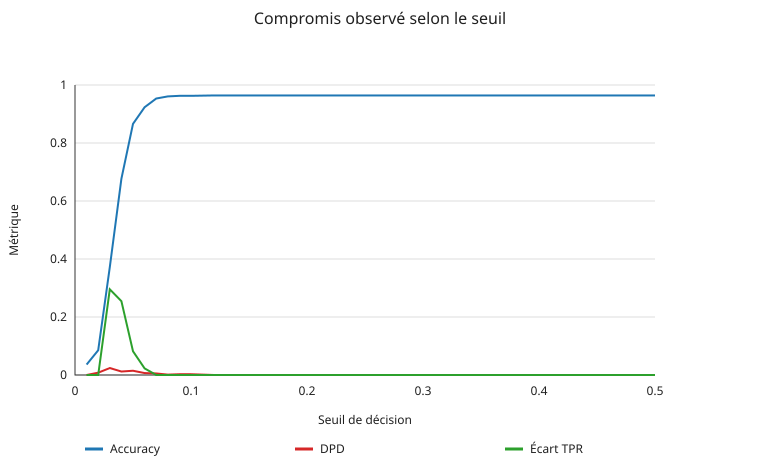

seuil  accuracy  dpd   eod


0.010   0.036   0.000  0.000


0.030   0.372   0.024  0.295


0.040   0.677   0.012  0.255


0.050   0.866   0.015  0.082


0.070   0.953   0.005  0.000


0.090   0.963   0.003  0.000


0.120   0.964   0.000  0.000


0.500   0.964   0.000  0.000


In [11]:
// Chaque seuil recalcule les décisions ; la grille reste celle du protocole source.
(double Accuracy, double DPD, double EOD) ThresholdMetrics(double[] p, int[] y, int[] groups, double threshold)
{
    var pred = p.Select(v => v >= threshold ? 1 : 0).ToArray();
    var a = Metrics(y, pred, groups, 0);
    var b = Metrics(y, pred, groups, 1);
    return (Accuracy(y, pred), Math.Abs(a.PP - b.PP), Math.Abs(a.TPR - b.TPR));
}

var thresholds = Enumerable.Range(1, 15).Select(i => i * .01).Concat(Enumerable.Range(0, 7).Select(i => .20 + i * .05)).ToArray();
var frontier = thresholds.Select(t => ThresholdMetrics(pTest, yTest, gTest, t)).ToArray();
display(SvgChart("Compromis observé selon le seuil", "Seuil de décision", "Métrique", new[] { ("Accuracy", thresholds, frontier.Select(r => r.Accuracy).ToArray(), "#1f77b4"), ("DPD", thresholds, frontier.Select(r => r.DPD).ToArray(), "#d62728"), ("Écart TPR", thresholds, frontier.Select(r => r.EOD).ToArray(), "#2ca02c") }, xMax: .5), "image/svg+xml");
Console.WriteLine("seuil  accuracy  dpd   eod");
foreach (int i in new[]
{
    0,
    2,
    3,
    4,
    6,
    8,
    11,
    21
}

)
    Console.WriteLine($"{thresholds[i]:F3}   {frontier[i].Accuracy:F3}   {frontier[i].DPD:F3}  {frontier[i].EOD:F3}");


**Lecture du graphique.** Sur ce test, au seuil 0.01 le modele predit tout positif et la parite est triviale. Au seuil 0.03, le tableau montre un ecart de rappel entre groupes ; au seuil 0.05, l'accuracy augmente et un ecart subsiste. A 0.09 des predictions positives persistent ; a 0.12 elles disparaissent et la parite redevient triviale. Cette grille illustre des compromis sur un tirage, sans prouver qu'une egalite utile soit inaccessible en general.

***

## 5. Deux mitigations comparees sur le meme split

Maintenant qu'on a mesure le conflit, on teste **deux strategies correctives** sur le meme train/test split :

1. **Reweighting** : on **reequilibre les poids d'entrainement** pour que le modele voie chaque combinaison (groupe x label) avec une importance egale. L'attribut groupe est utilise *a l'entrainement uniquement*, jamais a l'inference.
2. **Seuils par groupe** (*thresholding*) : on garde un seul modele, mais on **applique un seuil different par groupe** a l'inference pour egaliser un taux de decision (typiquement le TPR — egalite des chances).

Pour chaque mitigation, on **precise ou l'attribut groupe est utilise** (entrainement ? calibrage ? inference ?) — c’est une information nécessaire pour analyser le système et ses usages ; les obligations juridiques exactes dépendent du contexte et ne sont pas démontrées par ce carnet.


In [12]:
// Poids inverses par cellule groupe×label ; le groupe n'entre pas dans les variables prédictives.
double[] Reweight(int[] groups, int[] labels)
{
    var weights = new double[labels.Length];
    for (int g = 0; g < 2; g++)
        for (int y = 0; y < 2; y++)
        {
            var ids = Enumerable.Range(0, labels.Length).Where(i => groups[i] == g && labels[i] == y).ToArray();
            foreach (int i in ids)
                weights[i] = labels.Length / (4.0 * ids.Length);
        }

    return weights;
}

var weightsTrain = Reweight(gTrain, yTrain);
var weighted = FitLogistic(weightsTrain);
var pWeighted = Doubles(weighted.GetProperty("test"));
var yWeighted = pWeighted.Select(p => p >= .5 ? 1 : 0).ToArray();
var weightedA = Metrics(yTest, yWeighted, gTest, 0);
var weightedB = Metrics(yTest, yWeighted, gTest, 1);
Console.WriteLine("Reweighting : groupe utilisé à l'entraînement uniquement");
PrintMetrics("Pondéré A", weightedA);
PrintMetrics("Pondéré B", weightedB);
Console.WriteLine($"DPD={Math.Abs(weightedA.PP - weightedB.PP):F3} ; EOD={Math.Abs(weightedA.TPR - weightedB.TPR):F3} ; accuracy={Accuracy(yTest, yWeighted):F3}");


Reweighting : groupe utilisé à l'entraînement uniquement


Pondéré A    n= 750 accuracy=0.543 TPR=0.800 FPR=0.461 PP=0.465 prevalence=0.013


Pondéré B    n= 750 accuracy=0.551 TPR=0.455 FPR=0.443 PP=0.444 prevalence=0.059


DPD=0.021 ; EOD=0.345 ; accuracy=0.547


In [13]:
// Sélection uniquement sur calibration : les labels test ne choisissent ni cible ni seuil.
double EqualizeTpr(double[] p, int[] y, int[] groups, int label, double target)
{
    var positives = Enumerable.Range(0, y.Length).Where(i => groups[i] == label && y[i] == 1).ToArray();
    if (positives.Length == 0)
        throw new ArgumentException("Aucun positif de calibration");
    var candidates = Enumerable.Range(0, 95).Select(i => .01 + i * (.94 / 94)).ToArray();
    // La grille finie approche la cible ; le premier seuil départage les ex æquo.
    return candidates.OrderBy(t => Math.Abs(positives.Count(i => p[i] >= t) / (double)positives.Length - target)).First();
}

(double A, double B, int[] Pred) GroupThresholds(double target)
{
    double a = EqualizeTpr(pCal, yCal, gCal, 0, target), b = EqualizeTpr(pCal, yCal, gCal, 1, target);
    return (a, b, Enumerable.Range(0, yTest.Length).Select(i => pTest[i] >= (gTest[i] == 0 ? a : b) ? 1 : 0).ToArray());
}

(double Lower, double Upper) Wilson(int k, int n, double z = 1.96)
{
    if (n == 0)
        return (double.NaN, double.NaN);
    // Wilson exprime l’incertitude du taux binomial ; ce n’est pas un test d’égalité entre groupes.
    double p = k / (double)n, denominator = 1 + z * z / n;
    double centre = (p + z * z / (2 * n)) / denominator;
    double margin = z * Math.Sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator;
    return (Math.Max(0, centre - margin), Math.Min(1, centre + margin));
}

var calBaselinePred = pCal.Select(p => p >= .5 ? 1 : 0).ToArray();
double baselineTarget = (Metrics(yCal, calBaselinePred, gCal, 0).TPR + Metrics(yCal, calBaselinePred, gCal, 1).TPR) / 2;
var thresholdBaseline = GroupThresholds(baselineTarget);
var thresholdUseful = GroupThresholds(.5);
foreach (var(name, target, run)in new[]
{
    ("Cible baseline", baselineTarget, thresholdBaseline),
    ("Cible fixée", .5, thresholdUseful)
}

)
{
    Console.WriteLine($"{name}={target:F3} : seuils A={run.A:F2}, B={run.B:F2}");
    Console.WriteLine($"Accuracy test={Accuracy(yTest, run.Pred):F3}, baseline={Accuracy(yTest, yPred):F3}");
    for (int g = 0; g < 2; g++)
    {
        double t = g == 0 ? run.A : run.B;
        var positives = Enumerable.Range(0, yCal.Length).Where(i => gCal[i] == g && yCal[i] == 1).ToArray();
        var m = Metrics(yTest, run.Pred, gTest, g);
        var ci = Wilson(m.TP, m.TP + m.FN);
        Console.WriteLine($"Calibration {(g == 0 ? "A" : "B")} : positifs={positives.Length}, TPR={positives.Count(i => pCal[i] >= t) / (double)positives.Length:F3}");
        Console.WriteLine($"Test : n={m.N}, positifs={m.TP + m.FN}, négatifs={m.TN + m.FP}, TPR={m.TPR:F3} Wilson[{ci.Lower:F3},{ci.Upper:F3}], FPR={m.FPR:F3}, FP={m.FP}");
    }

    Console.WriteLine($"Écart TPR test : {Math.Abs(Metrics(yTest, run.Pred, gTest, 0).TPR - Metrics(yTest, run.Pred, gTest, 1).TPR):F3}");
}


Cible baseline=0.000 : seuils A=0.06, B=0.07


Accuracy test=0.937, baseline=0.964


Calibration A : positifs=7, TPR=0.000


Test : n=750, positifs=10, négatifs=740, TPR=0.000 Wilson[0.000,0.278], FPR=0.046, FP=34


Calibration B : positifs=31, TPR=0.000


Test : n=750, positifs=44, négatifs=706, TPR=0.000 Wilson[0.000,0.080], FPR=0.008, FP=6


... (4 outputs left out)

Test : n=750, positifs=10, négatifs=740, TPR=0.200 Wilson[0.057,0.510], FPR=0.312, FP=231


Calibration B : positifs=31, TPR=0.387


Test : n=750, positifs=44, négatifs=706, TPR=0.455 Wilson[0.317,0.599], FPR=0.314, FP=222


Écart TPR test : 0.255


### 5.1 Comparaison des approches

La cible 0,5 est un choix de conception préspecifié, pas un résidu de la baseline. Si elle est hors de portée sur la grille de seuils [0,01 ; 0,95], le seuil retenu donne le TPR le plus proche atteignable sur cette grille en calibration, sans garantir la cible exacte ; les bornes de la grille font partie du compromis.

Les seuils sont ajustes sur calibration, puis evalues une seule fois sur test. La premiere cible herite du TPR moyen de la baseline sur calibration : si elle est nulle, deux TPR nuls ne constituent pas une egalite utile. La seconde cible, **0,5 fixee avant mesure**, demande de retrouver une partie des positifs ; la grille discrete et le petit nombre de positifs ne garantissent ni la cible ni l'egalite sur test.

Comparer les TPR, leurs intervalles de Wilson et les effectifs ci-dessus ; ces intervalles conditionnels aux seuils choisis ne quantifient pas l'incertitude de leur apprentissage. Comparer aussi les FPR et l'accuracy a la baseline : un gain de rappel a un cout en faux positifs. Une difference ponctuelle faible ne prouve pas une egalite dans la population.

**Lecture de ce tirage.** Le controle a cible 0,5 produit des rappels non nuls mais differents sur test, avec une forte hausse des faux positifs et une baisse d’accuracy. Il ne demontre donc pas une egalite des chances atteinte : c’est un contre-resultat pour cette calibration et ce test, pas une preuve generale d’impossibilite. Le tres petit nombre de positifs du groupe A rend sa mesure particulierement incertaine.


In [14]:
// Tableau à quatre approches, avec les trois lieux d'utilisation de l'attribut de groupe.
Console.WriteLine("approche                   accuracy  DPD    EOD    TPR A  TPR B   utilisation groupe");
foreach (var(name, usage, pred)in new[]
{
    ("Baseline0.5", "aucune", yPred),
    ("Reweighting0.5", "entraînement", yWeighted),
    ("Seuils cible baseline", "calibration/inférence", thresholdBaseline.Pred),
    ("Seuils cible0.5", "calibration/inférence", thresholdUseful.Pred)
}

)
{
    var a = Metrics(yTest, pred, gTest, 0);
    var b = Metrics(yTest, pred, gTest, 1);
    Console.WriteLine($"{name, -26} {Accuracy(yTest, pred):F3}    {Math.Abs(a.PP - b.PP):F3}  {Math.Abs(a.TPR - b.TPR):F3}  {a.TPR:F3}  {b.TPR:F3}   {usage}");
}

Console.WriteLine("Ces résultats décrivent ce test, sans garantir une parité hors échantillon.");
for (int g = 0; g < 2; g++)
    Console.WriteLine($"Écart TPR test {(g == 0 ? "A" : "B")} à cible0.5 : {Math.Abs(Metrics(yTest, thresholdUseful.Pred, gTest, g).TPR - .5):F3}");


approche                   accuracy  DPD    EOD    TPR A  TPR B   utilisation groupe


Baseline0.5                0.964    0.000  0.000  0.000  0.000   aucune


Reweighting0.5             0.547    0.021  0.345  0.800  0.455   entraînement


Seuils cible baseline      0.937    0.037  0.000  0.000  0.000   calibration/inférence


Seuils cible0.5            0.677    0.012  0.255  0.200  0.455   calibration/inférence


Ces résultats décrivent ce test, sans garantir une parité hors échantillon.


Écart TPR test A à cible0.5 : 0.300


Écart TPR test B à cible0.5 : 0.045


### 5.2 Implications reglementaires et operationnelles

Les deux mitigations different sur **ou va l'attribut groupe** dans la chaine de decision. C'est un point qu'aucune metrique d'equite ne decide seule :

| Mitigation | Entrainement | Calibrage | Inference | Implication |
|---|---|---|---|---|
| **Reweighting** | OK (poids d'entrainement) | non | non | Le groupe sert a **equilibrer les gradients** pendant l'apprentissage, mais le modele deploye ne le voit pas. Le groupe n'est pas utilise a l'inference ; la conformite et les usages admissibles dependent du contexte. |
| **Seuils par groupe** | non | OK (choix du seuil) | OK (seuil) | Le groupe sert a choisir les seuils sur calibration puis a les appliquer au moment de decider. Modele deploye reste aveugle, mais l'audit du seuil peut etre conteste (traitement differentie). |
| **Calibration par groupe** (exercice) | non | OK | OK | Le groupe selectionne le calibrateur sur chaque sous-population ; la calibration sur de nouvelles donnees reste a mesurer. |

**Aucune approche n'est neutre.** Toutes font un choix de societe — la technique ne fait que le rendre mesurable.

***

## 6. Analyse d'erreurs : la derniere poche cachee

Comme dans le notebook [2.13](2.13-Analyse-Erreurs.ipynb), l'aggregation masque des **poches d'erreur**. Nous en avons construit une volontairement des la generation (section 1.1, regle adverse cachee) : dans le groupe B (seniors), les dossiers avec `anciennete > 15 ans` ont une probabilite de defaut *plus elevee* que ce que le modele lineaire capte — une interaction groupe x anciennete invisible pour la baseline. Voyons si l'analyse par tranches la detecte.


Poche B, ancienneté>15 : 170 dossiers


Accuracy poche=0.918, hors poche=0.970


Taux d'erreur poche=0.082, hors poche=0.030


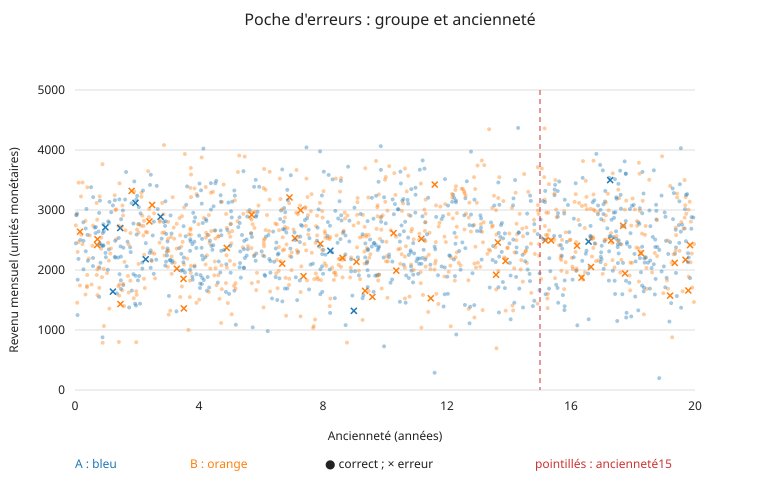

In [15]:
// La poche est définie avant cette mesure ; toute conclusion reste propre à la simulation.
var pocket = Enumerable.Range(0, yTest.Length).Where(i => gTest[i] == 1 && XTest[i][1] > 15).ToArray();
var outside = Enumerable.Range(0, yTest.Length).Except(pocket).ToArray();
double ErrorRate(int[] ids) => ids.Count(i => yTest[i] != yPred[i]) / (double)ids.Length;
Console.WriteLine($"Poche B, ancienneté>15 : {pocket.Length} dossiers");
Console.WriteLine($"Accuracy poche={1 - ErrorRate(pocket):F3}, hors poche={1 - ErrorRate(outside):F3}");
Console.WriteLine($"Taux d'erreur poche={ErrorRate(pocket):F3}, hors poche={ErrorRate(outside):F3}");
// Nuage natif : les 1500 observations, couleurs par groupe et croix pour erreurs.
var scatter = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='780' height='490' viewBox='0 0 780 490'><rect width='780' height='490' fill='white'/><g font-family='sans-serif' font-size='12' fill='#222'><text x='390' y='25' text-anchor='middle' font-size='16'>Poche d'erreurs : groupe et ancienneté</text>");
double IncomeMin = 0, IncomeMax = 5000;
double SX(double x) => 75 + 620 * x / 20;
double SY(double y) => 390 - 300 * (y - IncomeMin) / (IncomeMax - IncomeMin);
for (int k = 0; k <= 5; k++)
{
    scatter.Append($"<path d='M75 {SY(k * 1000):F3}H695' stroke='#ddd'/><text x='65' y='{SY(k * 1000) + 4:F3}' text-anchor='end'>{k * 1000}</text>");
    scatter.Append($"<text x='{SX(k * 4):F3}' y='410' text-anchor='middle'>{k * 4}</text>");
}

for (int i = 0; i < yTest.Length; i++)
{
    double x = SX(XTest[i][1]), y = SY(XTest[i][0]);
    string color = gTest[i] == 0 ? "#1f77b4" : "#ff7f0e";
    if (yTest[i] == yPred[i])
        scatter.Append($"<circle cx='{x:F3}' cy='{y:F3}' r='2' fill='{color}' opacity='.4'/>");
    else
        scatter.Append($"<path d='M{x - 3:F3} {y - 3:F3}l6 6m-6 0l6 -6' stroke='{color}' stroke-width='1.5'/>");
}

scatter.Append($"<path d='M{SX(15):F3} 90V390' stroke='#c33' stroke-dasharray='5 4'/><text x='385' y='440' text-anchor='middle'>Ancienneté (années)</text><text transform='translate(18 250) rotate(-90)' text-anchor='middle'>Revenu mensuel (unités monétaires)</text>");
scatter.Append("<text x='75' y='468' fill='#1f77b4'>A : bleu</text><text x='190' y='468' fill='#ff7f0e'>B : orange</text><text x='325' y='468'>● correct ; × erreur</text><text x='535' y='468' fill='#c33'>pointillés : ancienneté15</text></g></svg>");
display(new EquitySvg(scatter.ToString()), "image/svg+xml");


**Conclusion de l'analyse.** La mesure confirme la poche annoncee : taux d'erreur **0.082 dans la poche** (seniors du groupe B, anciennete > 15 ans) contre **0.030 hors poche** — un rapport de 2.7, invisible dans l'accuracy globale (0.964), visible uniquement quand on croise les attributs. C'est le meme geste que [2.13](2.13-Analyse-Erreurs.ipynb) : ne pas s'arreter a la moyenne. **Ici la moyenne cache en plus une inegalite** entre groupes.

***

## 7. Synthese et transition

Cinq lecons a retenir :

1. **L'accuracy globale n'est pas une garantie d'equite.** Elle peut etre elevee alors que les taux d'erreur par groupe divergent massivement. Toujours **decouper** la performance par sous-population avant de conclure.
2. **Trois definitions d'equite qui peuvent entrer en tension.** La parite demographique ignore les etiquettes reelles ; l'egalite des chances les utilise ; les chances egalisees contraignent TPR et FPR. Aucune n'est universelle — le choix est **contextuel** (reglementaire, metier, ethique).
3. **Quantifier l’incertitude.** Le bootstrap est une option, les intervalles de Wilson une autre pour les proportions. Un intervalle conditionnel ne décrit pas à lui seul toute l’incertitude d’apprentissage et ne tranche pas l’équité.
4. **Calibration, accuracy et parite peuvent entrer en conflit.** Les resultats theoriques dependent de leurs hypotheses et des metriques choisies. Le compromis est **quantitatif** : une frontiere, pas un debat moral.
5. **Les trois gestes du diagnostic se completent.** Tranches (equite par groupe), worst-k (analyse d'erreurs du 2.13), confiance (calibration du 2.5b). Une pratique honnete du ML superpose les trois vues.

**Position dans la serie.** Ce notebook **ferme le triptyque** commence en 2.5b (calibration) et prolonge en 2.13 (analyse d'erreurs). La suite logique est 2.6 (clustering) puis 2.7 (modeles non parametriques) : on a appris a mesurer, calibrer, diagnostiquer, et **trancher les arbitrages ethiques** ; on peut maintenant attaquer des modeles plus expressifs.

### Pour aller plus loin

- **Chouldechova (2017)** — *Fair prediction with disparate impact: A study of bias in recidivism prediction instruments* — étudie des incompatibilités conditionnelles entre calibration/prédictivité et taux d’erreur ; ce n’est pas une impossibilité générale de satisfaire les trois égalités de taux définies ici.
- **Hardt, Price, Srebro (2016)** — *Equality of Opportunity in Supervised Learning* — propose le seuils par groupe comme strategie d'egalisation des chances.
- **AI Act europeen (2024)** — repère réglementaire cité par le cours ; l’identification des obligations applicables demande une analyse juridique du système et de son contexte.

### Exemple guidé — le vrai calibrateur par groupe

Le canevas historique utilise `CalibratedClassifierCV` et `FrozenEstimator` (scikit-learn >=1.6). Nous l’exécutons réellement ici : apprentissage de la base sur train, calibrateurs sur calibration, mesure sur test. L’activité suivante étudiera un budget de calibration réduit ; cet exemple complet reste disponible.


In [16]:
// Exemple guidé : le véritable FrozenEstimator empêche le fit de la base sur calibration.
double[] CalibrateGroup(double[][] calibrationX, int[] calibrationY, double[][] evaluationX, string method = "isotonic")
{
    var result = Backend(@"
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
base=LogisticRegression(max_iter=1000).fit(cfg['XTrain'],cfg['yTrain'])
model=CalibratedClassifierCV(FrozenEstimator(base),method=cfg['method'])
model.fit(cfg['calibrationX'],cfg['calibrationY'])
result_json=json.dumps(model.predict_proba(cfg['evaluationX'])[:,1].tolist())
", new { XTrain, yTrain, calibrationX, calibrationY, evaluationX, method });
    return Doubles(result);
}

var pCalibrationFull = new double[yTest.Length];
for (int g = 0; g < 2; g++)
{
    var calIds = Enumerable.Range(0, yCal.Length).Where(i => gCal[i] == g).ToArray();
    // Chaque calibrateur voit son groupe, puis ses probabilités retrouvent les positions test d’origine.
    var testIds = Enumerable.Range(0, yTest.Length).Where(i => gTest[i] == g).ToArray();
    var probabilities = CalibrateGroup(calIds.Select(i => XCal[i]).ToArray(), calIds.Select(i => yCal[i]).ToArray(), testIds.Select(i => XTest[i]).ToArray());
    for (int j = 0; j < testIds.Length; j++)
        pCalibrationFull[testIds[j]] = probabilities[j];
}

var predictionCalFull = pCalibrationFull.Select(p => p >= .5 ? 1 : 0).ToArray();
Console.WriteLine("Calibration isotonique par groupe, toutes les données de calibration :");
PrintMetrics("Calibré A", Metrics(yTest, predictionCalFull, gTest, 0));
PrintMetrics("Calibré B", Metrics(yTest, predictionCalFull, gTest, 1));
Console.WriteLine($"Accuracy globale : {Accuracy(yTest, predictionCalFull):F3}");


Calibration isotonique par groupe, toutes les données de calibration :


Calibré A    n= 750 accuracy=0.987 TPR=0.000 FPR=0.000 PP=0.000 prevalence=0.013


Calibré B    n= 750 accuracy=0.941 TPR=0.000 FPR=0.000 PP=0.000 prevalence=0.059


Accuracy globale : 0.964


**Lecture de l’exemple guidé.** Sur ce tirage, la calibration isotonique par groupe garde une accuracy de 0,964 et des TPR nuls au seuil0,5 dans les deux groupes. Les scores peuvent changer sans modifier ces décisions ; ce résultat ne garantit ni utilité opérationnelle ni calibration hors échantillon.

### Exercice ouvert 3 — sensibilité au budget de calibration

L’exemple guidé précédent ajuste le véritable `CalibratedClassifierCV(FrozenEstimator(base), method="isotonic")` séparément par groupe. Étendre cette étude : conserver **75 %** de la calibration de chaque groupe, par séparation stratifiée sur le label (`random_state=2026`), et refaire les deux calibrateurs. Les indices sont fournis pour isoler le travail demandé : sélectionner les données, appeler le vrai helper de bibliothèque et remettre les scores dans l’ordre des observations d’évaluation.

Compléter `CalibrateBudget(evaluationX, evaluationGroups)` en utilisant `reducedIndices`. Renvoyer les **1500 probabilités**, sans réentraîner la base sur calibration ou test. Comparer DPD, écart TPR, accuracy et les cinq bins de calibration de chaque groupe à l’exemple complet ; préciser où le groupe intervient et ce que permet de conclure ce seul tirage. Une réduction de données ne garantit pas une détérioration monotone de toutes les métriques.

La garde contrôle la forme, la finitude et des valeurs/agrégats indépendants, puis refait l’appel avec les données d’évaluation inversées. Elle ne remplace ni la lecture de l’usage effectif de la bibliothèque ni la discussion des courbes.


Les 1500 valeurs sont contrôlées dans leur ordre, à précision 1e-8 ; la répétition sur l’ordre inversé vérifie également la réassociation aux observations.


In [17]:
// Exercice ouvert : train_test_split ne fournit que les indices de calibration à garder.
var budgetData = Backend(@"
from sklearn.model_selection import train_test_split
g=np.asarray(cfg['gCal']);y=np.asarray(cfg['yCal']);result=[]
for group in (0,1):
    ids=np.flatnonzero(g==group)
    chosen,_=train_test_split(ids,train_size=.75,random_state=2026,stratify=y[ids])
    result.append(chosen.tolist())
result_json=json.dumps(result)", new { gCal, yCal });
var reducedIndices = budgetData.EnumerateArray().Select(Ints).ToArray();
double[] CalibrateBudget(double[][] evaluationX, int[] evaluationGroups)
{
    // TODO : sélectionner reducedIndices[g], appeler CalibrateGroup, remettre les scores en ordre.
    return null;
}

var calibrationAnswers = new[]
{
    CalibrateBudget(XTest, gTest),
    // Inverser les observations teste l’alignement des scores, indépendamment de leur somme.
    CalibrateBudget(XTest.Reverse().ToArray(), gTest.Reverse().ToArray())
};
if (calibrationAnswers.All(r => r == null))
    Console.WriteLine("Exercice3 à compléter : calibration avec75% du budget.");
else
{
    for (int variant = 0; variant < 2; variant++)
    {
        var answer = calibrationAnswers[variant];
        Require(answer != null && answer.Length == 1500 && answer.All(p => double.IsFinite(p) && p >= 0 && p <= 1), "1500 probabilités finies requises");
        var v = variant == 0 ? answer : answer.Reverse().ToArray();
        Require(Math.Abs(v[0] - 0.0) < 1e-8, "Score 0 incorrect");
        Require(Math.Abs(v[1] - 0.0) < 1e-8, "Score 1 incorrect");
        Require(Math.Abs(v[13] - 0.1111111111111111) < 1e-8, "Score 13 incorrect");
        Require(Math.Abs(v[17] - 0.05179282868525897) < 1e-8, "Score 17 incorrect");
        Require(Math.Abs(v[75] - 0.015384615384615385) < 1e-8, "Score 75 incorrect");
        Require(Math.Abs(v[200] - 0.05179282868525897) < 1e-8, "Score 200 incorrect");
        Require(Math.Abs(v[499] - 0.05179282868525897) < 1e-8, "Score 499 incorrect");
        Require(Math.Abs(v[749] - 0.05179282868525897) < 1e-8, "Score 749 incorrect");
        Require(Math.Abs(v[999] - 0.05179282868525897) < 1e-8, "Score 999 incorrect");
        Require(Math.Abs(v[1200] - 0.05179282868525897) < 1e-8, "Score 1200 incorrect");
        Require(Math.Abs(v[1499] - 0.05179282868525897) < 1e-8, "Score 1499 incorrect");
        Require(Math.Abs(v.Sum() - 51.45580511640351) < 1e-7, "Somme des scores incorrecte");
        Require(Math.Abs(v.Sum(p => p * p) - 3.1899808019078537) < 1e-7, "Somme des carrés incorrecte");
        Require(TraceDigest(v) == "bc757cce8e010de36de08859cb98bf88a8458805e1378bb85064636fb75ce381", "Trace des 1500 probabilités incorrecte");
    }

    Console.WriteLine("Contrat calibration satisfait ; calculer les métriques et discuter les bins.");
}


Exercice3 à compléter : calibration avec75% du budget.


## 8. Repères guidés et prolongements

Les trois repères historiques ci-dessous restent disponibles avec leur canevas. Les trois activités ouvertes et gardées sont maintenant réparties après les métriques, le bootstrap et l’exemple de calibration. Aucune implémentation existante n’est remplacée par un stub.

### Repère guidé 1 — Mesurer les trois metriques a la main

Sur la table de controle de la section 2.1 (12 dossiers), recalculez **a la main** les trois metriques d'equite, puis verifiez votre calcul avec la cellule C# correspondante. Si votre calcul differe de la valeur numerique, **identifiez la case que vous avez confondue** (TPR/FPR/PP).

### Prolongement conceptuel — Construire un contre-exemple

Construisez deux matrices de confusion pour des groupes aux prevalences differentes, avec TPR et FPR egaux entre groupes. Quel classifieur constant realise aussi la parite demographique ? Expliquez pourquoi cette egalite triviale ne suffit pas a garantir une decision utile. Puis utilisez PP = prevalence × TPR + (1 − prevalence) × FPR pour trouver sous quelle condition deux groupes de prevalences differentes ayant les memes TPR et FPR peuvent avoir la meme proportion de predictions positives.

### Repère guidé 3 — Calibration par groupe

Relire la troisième approche exécutée dans l’exemple guidé : utilisez la cellule sur les seuils comme canevas, et remplacez la recherche de seuil par un appel a `sklearn.calibration.CalibratedClassifierCV` avec `FrozenEstimator` (scikit-learn >= 1.6) separement sur chaque groupe (re-entrainez le baseline pour disposer d'un estimateur frais). Comparez les trois metriques (DPD, EOD, accuracy) a celles du baseline et des deux autres mitigations. Quel est le meilleur compromis observe ?

In [18]:
// Les repères historiques restent guidés ; les activités ouvertes sont réparties plus haut.
Console.WriteLine("Table de contrôle : groupe, y réel, y prédit");
for (int i = 0; i < controlY.Length; i++)
    Console.WriteLine($"{controlGroup[i]} {controlY[i]} {controlPred[i]}");
Console.WriteLine("Recalculer TPR/FPR/PP à la main puis vérifier en section2.1.");
Console.WriteLine($"Prévalence A={resultA.Prevalence:F3}, B={resultB.Prevalence:F3}");
Console.WriteLine("Un classifieur toujours négatif donne TPR=FPR=PP=0 si les deux classes sont présentes.");
Console.WriteLine("Avec PP=prévalence*TPR+(1-prévalence)*FPR, déterminer quand des prévalences différentes donnent la même PP.");
Console.WriteLine("Calibration par groupe : l'exemple CalibrateGroup appelle réellement CalibratedClassifierCV(FrozenEstimator(base)).");
Console.WriteLine("Comparer DPD, EOD, accuracy et FPR à baseline, reweighting et seuils ; ne pas déduire une garantie hors test.");


Table de contrôle : groupe, y réel, y prédit


0 1 1


0 1 1


0 1 0


0 0 0


0 0 0


... (9 outputs left out)

Un classifieur toujours négatif donne TPR=FPR=PP=0 si les deux classes sont présentes.


Avec PP=prévalence*TPR+(1-prévalence)*FPR, déterminer quand des prévalences différentes donnent la même PP.


Calibration par groupe : l'exemple CalibrateGroup appelle réellement CalibratedClassifierCV(FrozenEstimator(base)).


Comparer DPD, EOD, accuracy et FPR à baseline, reweighting et seuils ; ne pas déduire une garantie hors test.


## References

1. **Chouldechova, A. (2017).** *Fair prediction with disparate impact: A study of bias in recidivism prediction instruments*. Big Data, 5(2), 153-163. — Etudie les tensions entre calibration et parite des erreurs sous des hypotheses precisees.
2. **Hardt, M., Price, E., & Srebro, N. (2016).** *Equality of Opportunity in Supervised Learning*. NeurIPS 2016. — Introduit l'egalisation des chances par seuils par groupe.
3. **Kamiran, F., & Calders, T. (2012).** *Data preprocessing techniques for classification without discrimination*. Knowledge and Information Systems, 33(1), 1-33. — Le reweighting comme methode de pré-traitement.
4. **Verma, S., & Rubin, J. (2018).** *Fairness definitions explained*. FairWare Workshop. — Taxonomie des definitions de fairness (parite demographique, egalite des chances, etc.).
5. **AI Act europeen (Regulation 2024/1689).** Article 10 — exigences de qualite des donnees pour les systemes a haut risque : documentation de l'utilisation d'attributs sensibles.
6. **Mehrabi, N., Morstatter, F., Saxena, N., Lerman, K., & Galstyan, A. (2021).** *A Survey on Bias and Fairness in Machine Learning*. ACM Computing Surveys, 54(6). — Revue des definitions et methodes de mitigation.

Références et descriptions héritées du Python versionné ; ce portage ne revendique pas de nouvelle lecture indépendante des articles ni d’analyse juridique du texte réglementaire.
